# Pyro examples, with simpler model definitions
Three runnable examples from official Pyro material: a noisy scale, regression with an interaction, and a hierarchy for eight schools. Each section links its source and identifies any changed assumptions. The Python model contains the probability relationships; generation, conditioning and inference are separate calls.

Run this notebook with the project's `vi` and `notebook` extras installed. The first example is exact; the others use approximate VI.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found.*", module="tqdm.auto")

import numpy as np
import matplotlib.pyplot as plt
from smallprob import model, Normal, HalfNormal
from examples.pyro_gallery import (
    interaction_data, interaction_known_noise, interaction_reference,
    SCHOOL_EFFECTS, SCHOOL_SE, schools_reference, pyro_log_joint_checks,
)

from smallprob.plotting import use_style
from matplotlib_inline.backend_inline import set_matplotlib_formats

use_style()  # readable labels, 150-dpi display, 300-dpi file export
set_matplotlib_formats("svg", "retina")  # sharp at any zoom + high-resolution PNG

## 1. How much does the object weigh?
Source: [Pyro's scale example](https://pyro.ai/examples/intro_part_ii.html). Pyro labels this older tutorial deprecated, but the example is still useful. This is the same probability model: a prior guess of 8.5, prior SD 1, and measurement SD 0.75. We observe 9.5.

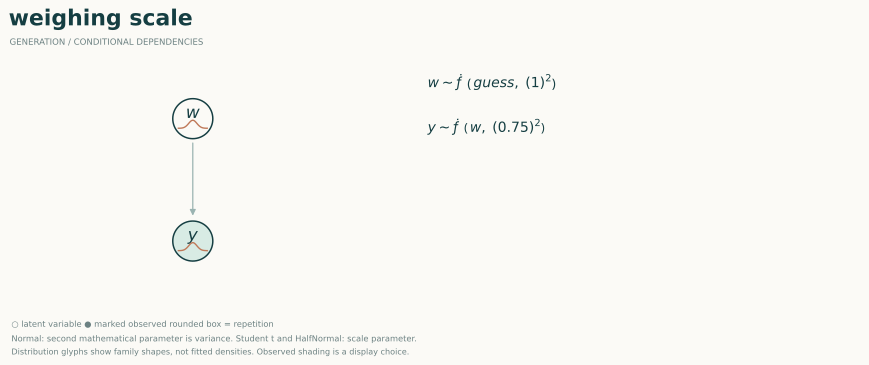

In [2]:
@model
def weighing_scale(guess=8.5):
    weight = Normal(guess, 1)
    measurement = Normal(weight, 0.75)

scale = weighing_scale()
scale.diagram(labels={"weight": "w", "measurement": "y"}, observed=["measurement"])

In [3]:
generated = scale.simulate(draws=5, seed=7)
print("Five generated measurements:", generated["measurement"].round(2))
p_weight = scale.infer(measurement=9.5)
print(f"Exact posterior: mean = {p_weight.mean('weight'):.2f}, SD = {p_weight.sd('weight'):.2f}")
assert np.isclose(p_weight.mean("weight"), 9.14)
assert np.isclose(p_weight.sd("weight"), 0.60)

Five generated measurements: [8.73 7.56 7.3  9.57 7.54]
Exact posterior: mean = 9.14, SD = 0.60


Normal conditioning gives the answer directly:
$$v=\left(1+\frac{1}{0.75^2}\right)^{-1}=0.36,\qquad m=v\left(8.5+\frac{9.5}{0.75^2}\right)=9.14.$$
The posterior SD is $\sqrt{v}=0.60$.

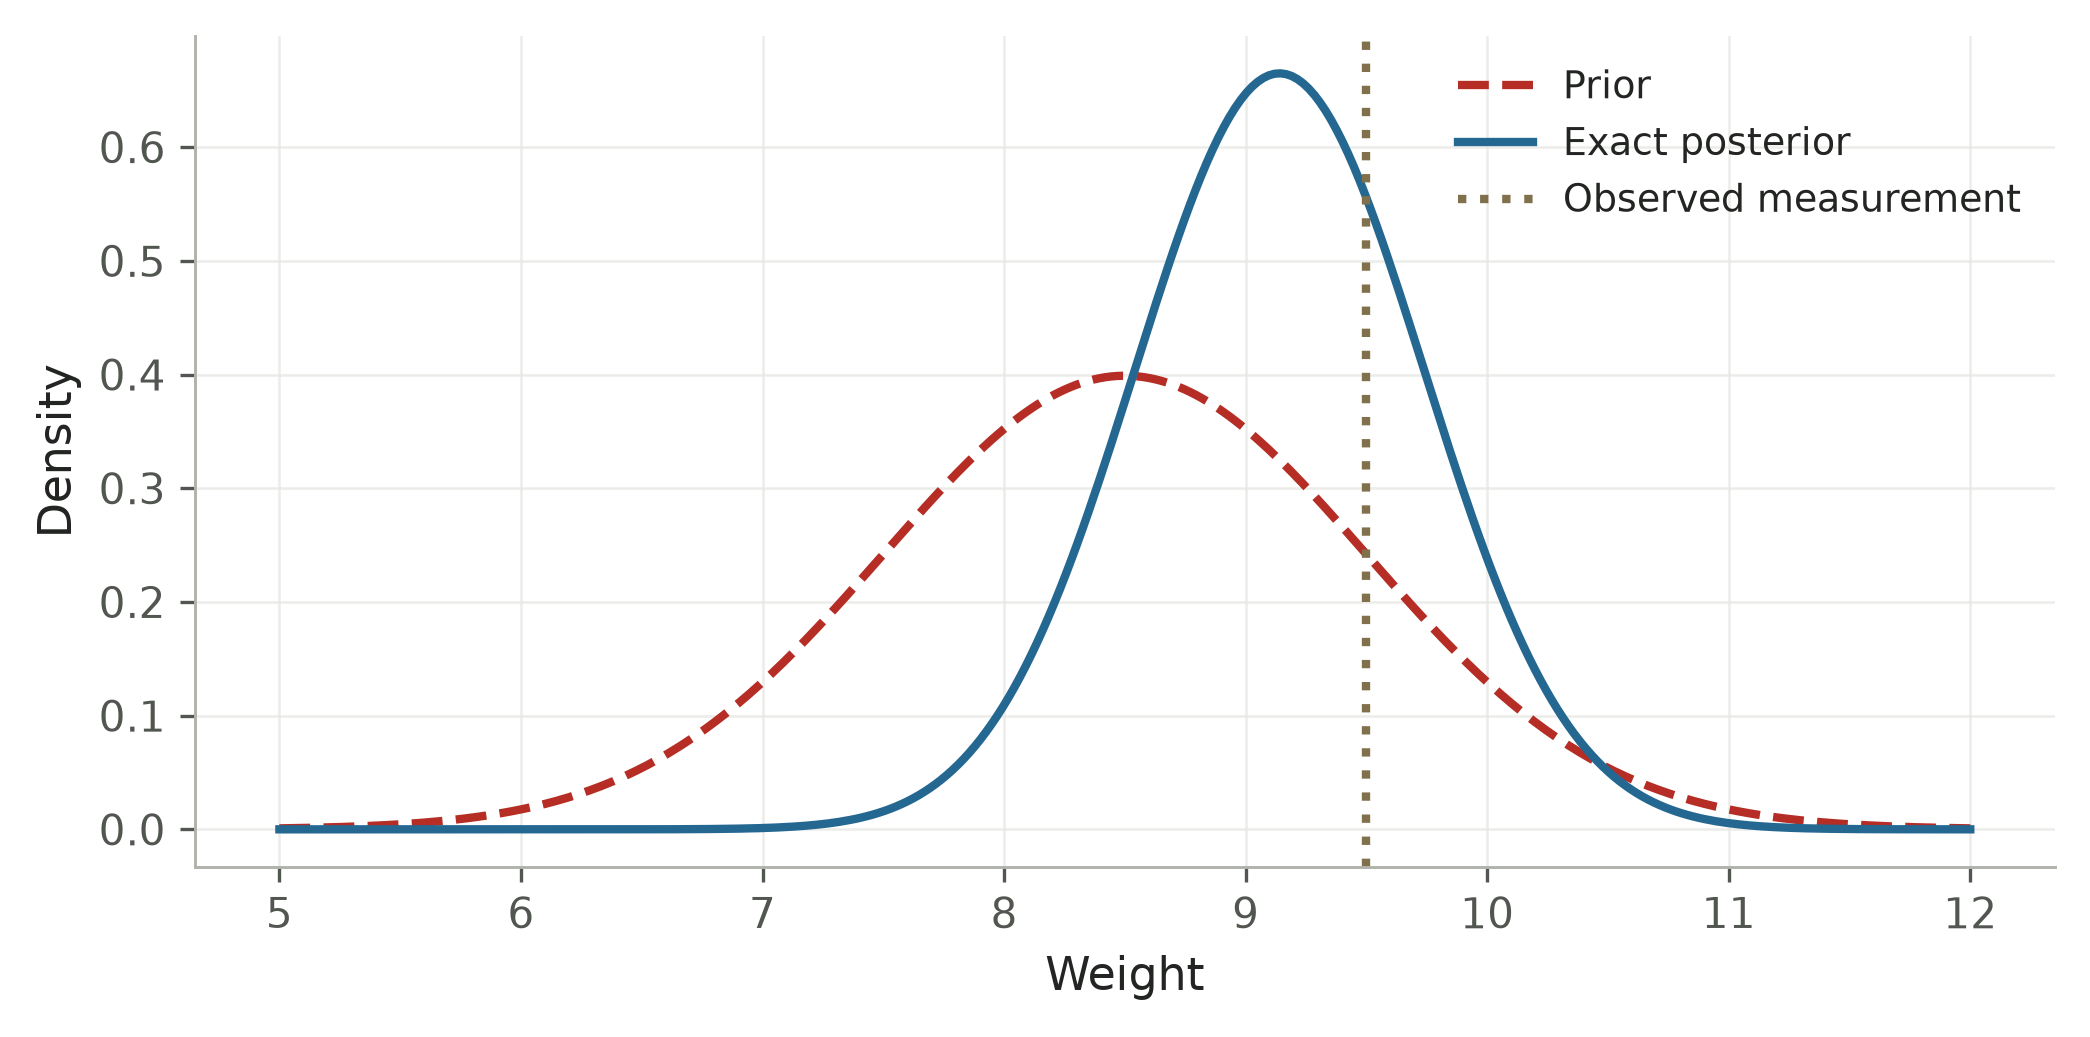

In [4]:
grid = np.linspace(5, 12, 300)
def normal_density(values, mean, sd):
    return np.exp(-0.5 * ((values - mean) / sd)**2) / (sd * np.sqrt(2 * np.pi))

plt.plot(grid, normal_density(grid, 8.5, 1), "--", label="Prior")
plt.plot(grid, normal_density(grid, 9.14, 0.6), label="Exact posterior")
plt.axvline(9.5, color="#80704b", linestyle=":", label="Observed measurement")
plt.xlabel("Weight"); plt.ylabel("Density"); plt.legend(); plt.show()

## 2. Does the slope differ between groups?
Source: [Pyro's regression example](https://pyro.ai/examples/intro_long.html#example-from-maximum-likelihood-regression-to-bayesian-regression). We preserve its intercept, two predictors and interaction, with Normal coefficient priors. **Adaptation:** use a fixed synthetic dataset instead of GDP data, and HalfNormal(1) instead of Uniform(0, 10) for the noise SD. The prior change changes the model.

Group 0 has slope `slope`. Group 1 has slope `slope + interaction`. Each predictor is an ordinary one-dimensional array.

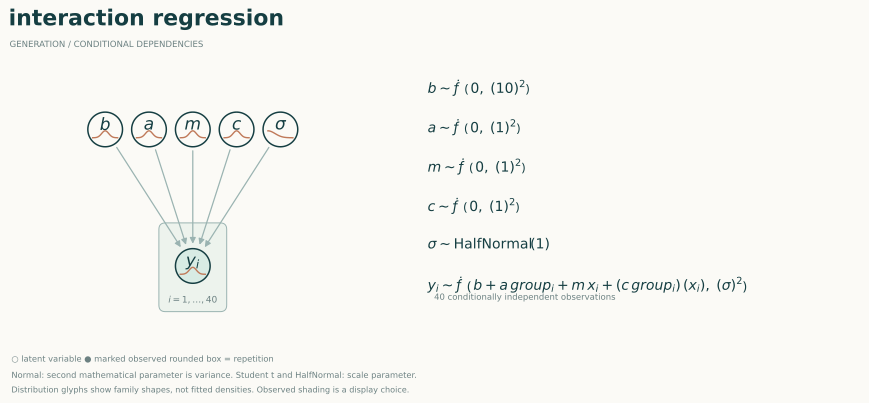

In [5]:
@model
def interaction_regression(group, x):
    intercept = Normal(0, 10)
    group_effect = Normal(0, 1)
    slope = Normal(0, 1)
    interaction = Normal(0, 1)
    sigma = HalfNormal(1)
    y = Normal(intercept + group_effect * group + slope * x + interaction * group * x, sigma)

group, x, y, truth = interaction_data()  # generated from this model at fixed parameters
regression = interaction_regression(group, x)
regression.diagram(labels={"intercept": "b", "slope": "m", "group_effect": "a", "interaction": "c"}, observed=["y"])

In [6]:
p_interaction = regression.infer(y=y, method="vi", steps=4000, seed=11)
low, high = p_interaction.interval("interaction")
print(f"Interaction mean: {p_interaction.mean('interaction'):.3f}")
print(f"95% guide interval: [{low:.3f}, {high:.3f}]")
print(f"Learned noise SD: {p_interaction.mean('sigma'):.3f}")

# A companion with a supplied noise SD permits an exact comparison.
p_known = interaction_known_noise(group, x, noise=0.5).infer(y=y)
print(f"Known-noise exact interaction mean: {p_known.mean('interaction'):.3f}")

Interaction mean: 0.833
95% guide interval: [0.487, 1.180]
Learned noise SD: 0.526
Known-noise exact interaction mean: 0.833


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


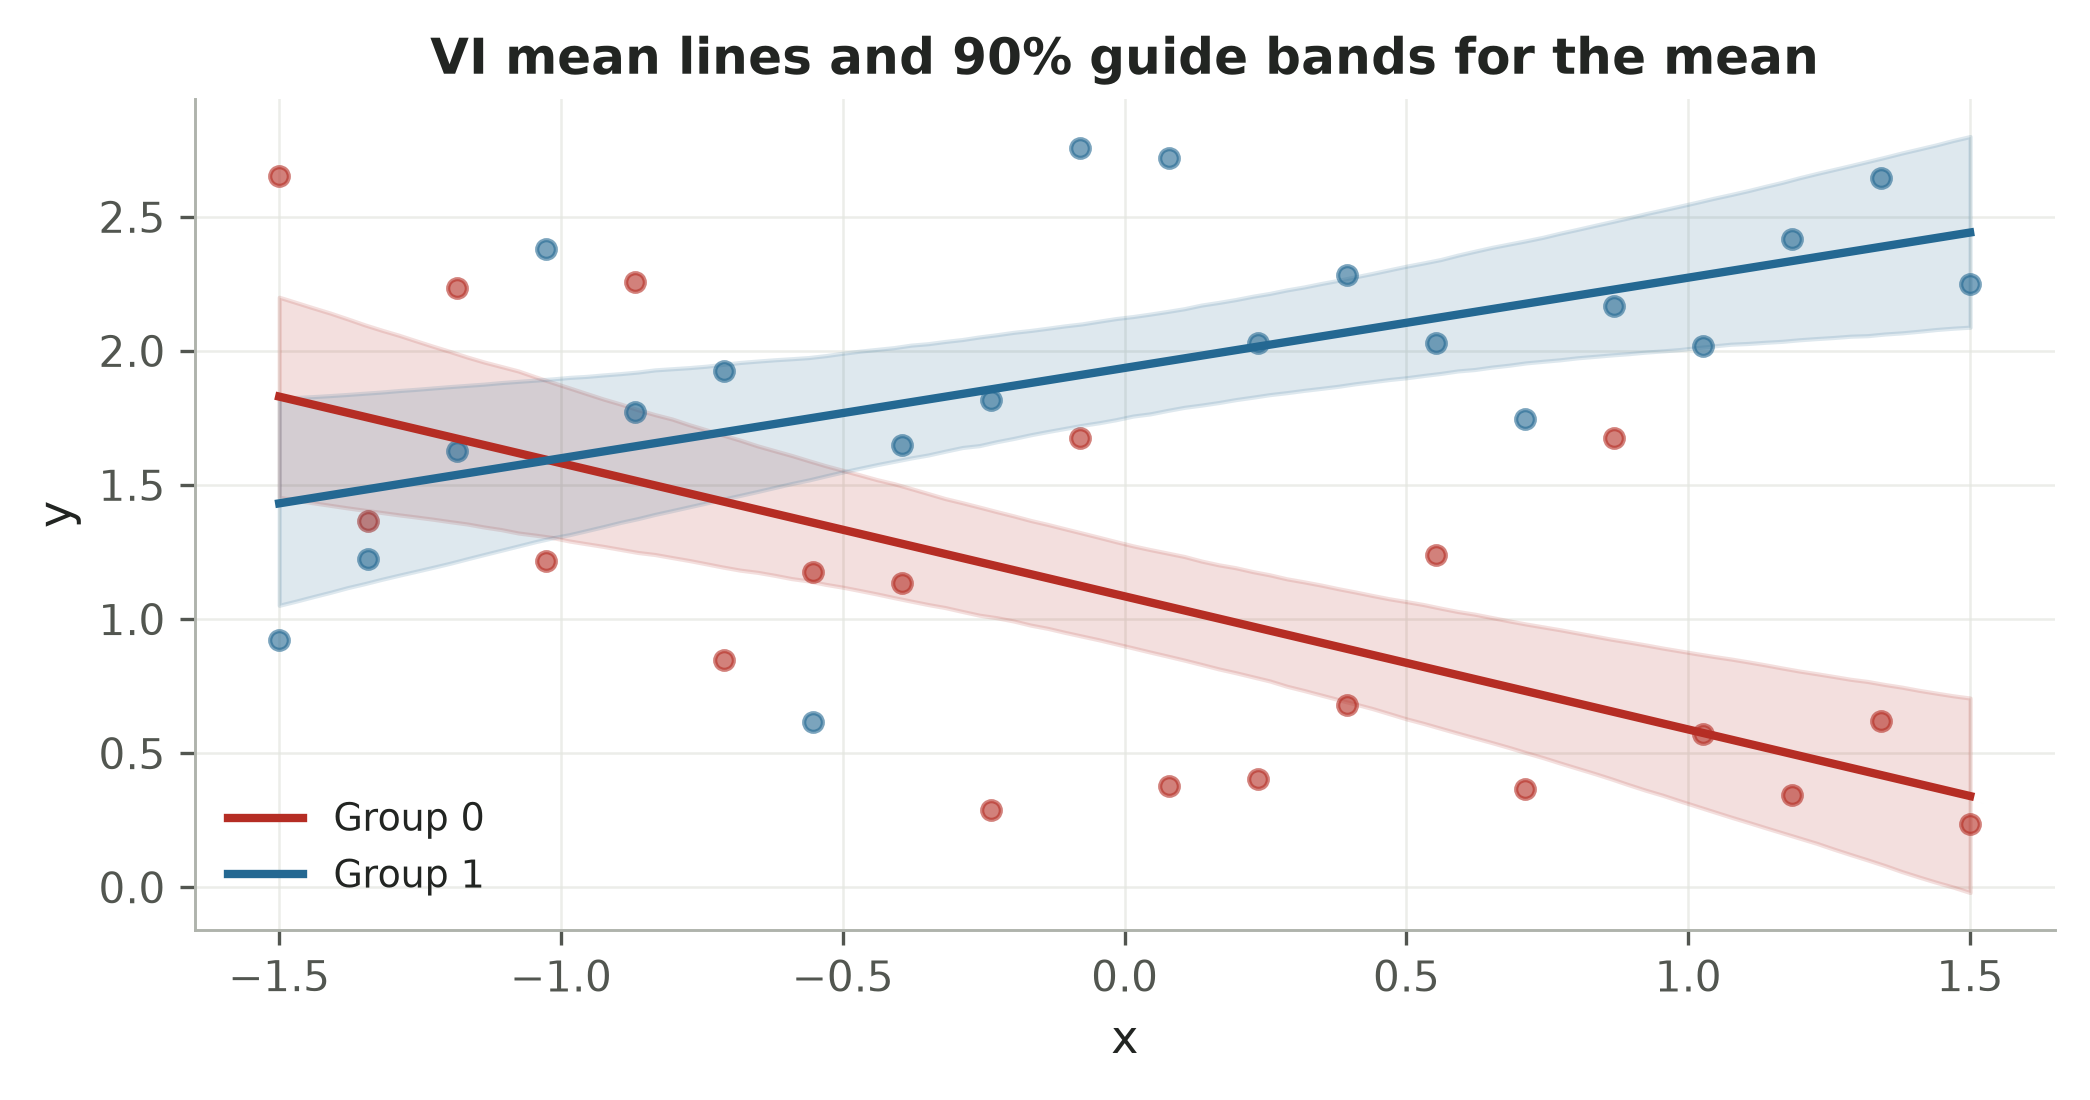

In [7]:
draws = p_interaction.sample(2000, seed=12)
grid = np.linspace(x.min(), x.max(), 100)
for g, color in [(0, "#b52d24"), (1, "#246892")]:
    selected = group == g
    lines = (draws["intercept"][:, None] + g * draws["group_effect"][:, None]
             + (draws["slope"] + g * draws["interaction"])[:, None] * grid)
    low, high = np.quantile(lines, [0.05, 0.95], axis=0)
    plt.scatter(x[selected], y[selected], s=20, alpha=0.6, color=color)
    plt.plot(grid, lines.mean(axis=0), color=color, label=f"Group {g}")
    plt.fill_between(grid, low, high, color=color, alpha=0.15)
plt.xlabel("x"); plt.ylabel("y")
plt.title("VI mean lines and 90% guide bands for the mean")
plt.legend(); plt.show()

The shaded bands describe uncertainty in the mean response under the fitted guide. They do not include new observation noise. The exact companion fixes the noise SD; it is a different inference problem from learning that SD.

## 3. What can eight schools learn from one another?
Source: [Pyro's Eight Schools model](https://github.com/pyro-ppl/pyro/blob/1.9.1/examples/eight_schools/mcmc.py) and [published observations](https://github.com/pyro-ppl/pyro/blob/1.9.1/examples/eight_schools/data.py). These eight estimates and standard errors are **not synthetic**.

Each school has an effect `mu + tau * eta`. The schools share an unknown population mean and amount of variation. **Adaptation:** replace Pyro's HalfCauchy(25) prior on `tau` with HalfNormal(5), and use VI instead of NUTS. HalfCauchy and NUTS are not implemented here. This example therefore has a different posterior from Pyro's original.

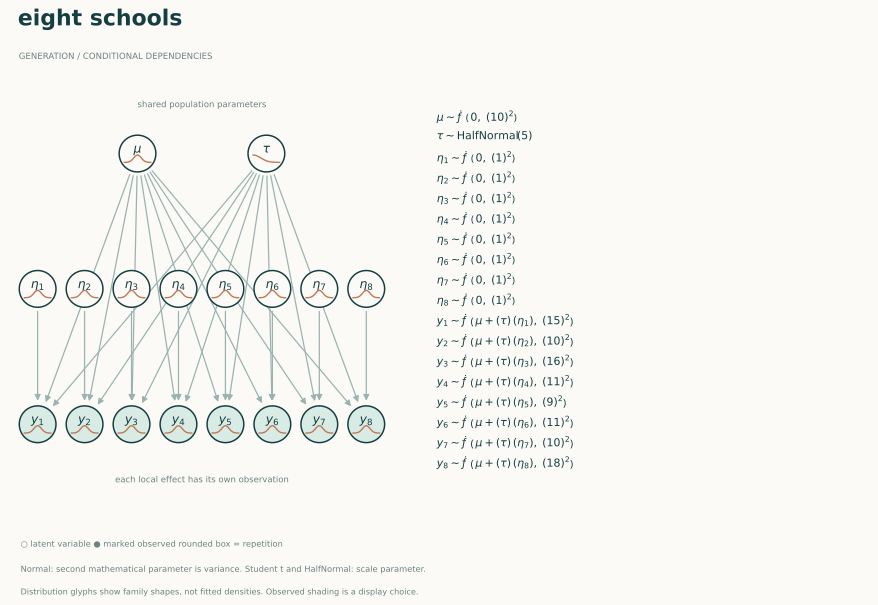

In [8]:
@model
def eight_schools(se):
    mu = Normal(0, 10)
    tau = HalfNormal(5)
    eta = Normal(np.zeros(len(se)), 1)
    y = Normal(mu + tau * eta, se)

schools = eight_schools(SCHOOL_SE)
schools.diagram(observed=["y"])

In [9]:
generated_schools = schools.simulate(draws=2, seed=7)
print("Prior predictive shape:", generated_schools["y"].shape)

p_schools = schools.infer(y=SCHOOL_EFFECTS, method="vi", steps=4000, seed=11)
print(f"Population mean: {p_schools.mean('mu'):.3f}")
print(f"Between-school scale: {p_schools.mean('tau'):.3f}")
draws = p_schools.sample(6000, seed=12)
effects = draws["mu"][:, None] + draws["tau"][:, None] * draws["eta"]

Prior predictive shape: (2, 8)


Population mean: 6.498
Between-school scale: 3.072


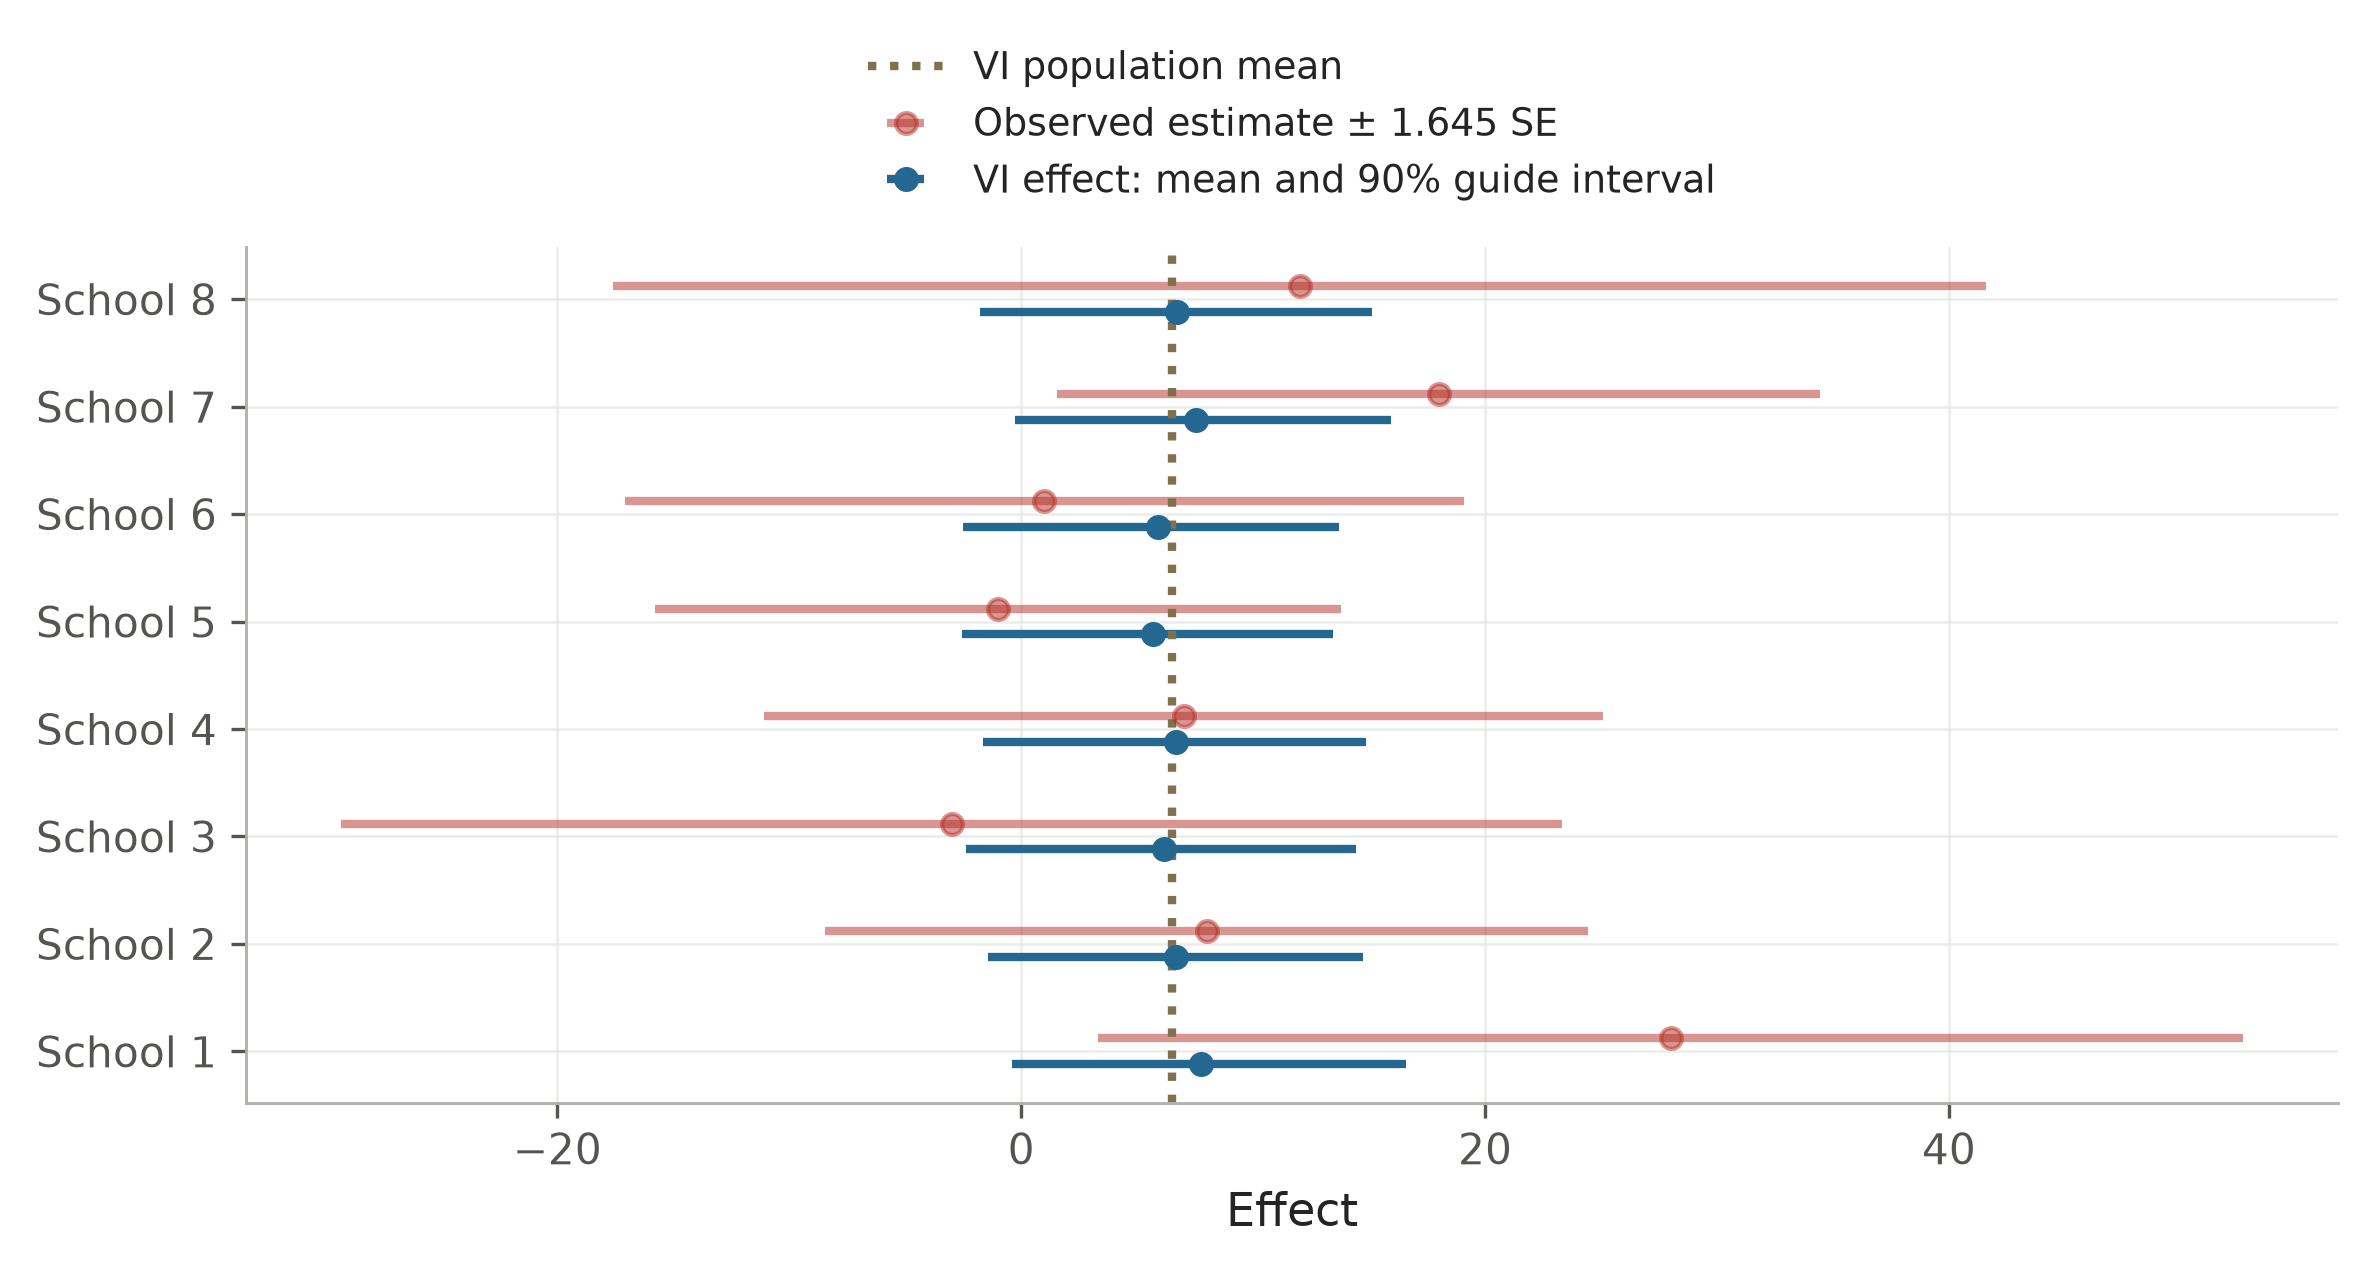

In [10]:
positions = np.arange(8)
means = effects.mean(axis=0)
low, high = np.quantile(effects, [0.05, 0.95], axis=0)
plt.figure(figsize=(8, 4.5))
plt.errorbar(SCHOOL_EFFECTS, positions + 0.12, xerr=1.645 * SCHOOL_SE,
             fmt="o", alpha=0.5, label="Observed estimate ± 1.645 SE")
plt.errorbar(means, positions - 0.12, xerr=[means - low, high - means],
             fmt="o", label="VI effect: mean and 90% guide interval")
plt.axvline(p_schools.mean("mu"), linestyle=":", color="#80704b", label="VI population mean")
plt.yticks(positions, [f"School {i + 1}" for i in positions])
plt.xlabel("Effect")
plt.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, 1.27))
plt.tight_layout(); plt.show()

The effects move toward a shared population estimate. Compute them from joint draws of `mu`, `tau` and `eta` to retain posterior dependence. The intervals remain guide approximations, especially in the tails.

## Check the translations
The following checks run now. Independent Pyro implementations use the **adapted probability laws above**. For both VI examples, one-dimensional numerical integration provides an independent reference for parameter means and SDs. These moment checks do not establish accurate tail probabilities or convergence for other datasets.

In [11]:
joint_checks = pyro_log_joint_checks()
print("Largest joint-density difference from equivalent Pyro models:",
      max(check["absolute_error"] for check in joint_checks))

cases = [
    ("Interaction", p_interaction,
     ["intercept", "group_effect", "slope", "interaction", "sigma"],
     interaction_reference(group, x, y)),
    ("Schools hyperparameters", p_schools, ["mu", "tau"], schools_reference()),
]
for label, posterior, names, reference in cases:
    mean = np.array([posterior.mean(name) for name in names])
    sd = np.array([posterior.sd(name) for name in names])
    mean_error = np.max(np.abs(mean - reference["mean"]) / reference["sd"])
    sd_error = np.max(np.abs(sd / reference["sd"] - 1))
    print(f"{label}: largest mean error = {mean_error:.3f} reference SD; SD error = {sd_error:.1%}")
    assert mean_error < 0.35 and sd_error < 0.20  # existing, predeclared limits

Largest joint-density difference from equivalent Pyro models: 7.105427357601002e-15
Interaction: largest mean error = 0.126 reference SD; SD error = 9.5%
Schools hyperparameters: largest mean error = 0.083 reference SD; SD error = 7.4%


The complete report also checks grid refinement and range expansion. Run `python -m examples.pyro_gallery` to regenerate it. The separate `smallprob.neural.VAE` helper adds minibatch neural training for binary observations. General Bernoulli/logistic graphs, learned mixture weights and discrete VI still need additional support in `@model`.